AI Usage Acknowledgment:

Generative AI was used to assist with
boilerplate code, the Streamlit dashboard, and debugging. All results were
run, checked and interpreted by me.

In [ ]:
!pip -q install "scikit-learn>=1.4,<2" "xgboost>=2,<4" "lightgbm>=4,<5" "catboost>=1.2,<2" "statsmodels>=0.14,<1" joblib plotly


In [ ]:
%pip install -q catboost lightgbm xgboost statsmodels


In [ ]:
import os, json, warnings
warnings.filterwarnings('ignore')
import pickle
import numpy as np, pandas as pd, joblib
from sklearn.ensemble import (
 RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
 StackingRegressor
)
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [ ]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('dengue_data.csv', parse_dates=['week_start_date'])
display(df.head())
print('Shape:', df.shape)
print('Districts:', sorted(df['district'].unique()))

Saving dengue_data.csv to dengue_data.csv


,year,week,week_start_date,week_end_date,district,cases,temp_avg_c,temp_max_c,temp_min_c,humidity_pct,rainfall_mm
0,2006,52,2006-12-23,2006-12-29,Colombo,71,24.84,28.22,22.37,83.54,9.62
1,2006,52,2006-12-23,2006-12-29,Gampaha,12,24.84,28.22,22.37,83.54,9.62
2,2006,52,2006-12-23,2006-12-29,Kandy,20,22.21,26.43,19.25,89.28,4.48
3,2007,1,2006-12-30,2007-01-05,Colombo,40,23.45,27.35,19.99,77.15,1.50
4,2007,1,2006-12-30,2007-01-05,Gampaha,11,23.45,27.35,19.99,77.15,1.50


Shape: (2973, 11)
Districts: ['Colombo', 'Gampaha', 'Kandy']


In [ ]:
print(df.isna().sum())
print('Duplicate district-weeks:', df.duplicated(['district','week_start_date']).sum())
print('Date range:', df.week_start_date.min(), df.week_start_date.max())
print('Negative cases:', (df.cases < 0).sum())


year               0
week               0
week_start_date    0
week_end_date      0
district           0
cases              0
temp_avg_c         0
temp_max_c         0
temp_min_c         0
humidity_pct       0
rainfall_mm        0
dtype: int64
Duplicate district-weeks: 0
Date range: 2006-12-23 00:00:00 2025-12-13 00:00:00
Negative cases: 0


### Dataset Exploration

The dataset was explored to understand the structure and characteristics of historical weekly dengue case records in Sri Lanka. The analysis examined the available variables, missing values, duplicate records, date range, and invalid case counts.

These checks are important because data quality directly affects machine learning performance. Identifying missing or inconsistent observations before training helps improve the reliability of the forecasting process.

The study focuses on Colombo district to ensure that the models learn patterns from a consistent geographical time series.

In [ ]:
colombo = df[df['district'] == 'Colombo'].copy()
colombo = colombo.sort_values('week_start_date').reset_index(drop=True)
print('Original Colombo rows:', len(colombo))


Original Colombo rows: 991


In [ ]:
LAGS = [1,2,3,4,8,12,26,52]
for lag in LAGS:
 colombo[f'cases_lag_{lag}'] = colombo['cases'].shift(lag)
print(colombo[['cases','cases_lag_1']].head())


   cases  cases_lag_1
0     71          NaN
1     40         71.0
2     43         40.0
3     38         43.0
4     52         38.0


In [ ]:

for column in ['rainfall_mm', 'temp_avg_c', 'humidity_pct']:
    for lag in [1, 2, 4]:
        colombo[f'{column}_lag_{lag}'] = colombo[column].shift(lag)

print('Climate lag features created.')


Climate lag features created.


In [ ]:

climate_columns = [
    c for c in colombo.columns
    if '_lag_' in c and c.startswith(
        ('rainfall_mm', 'temp_avg_c', 'humidity_pct')
    )
]

print("Number of climate lag features:", len(climate_columns))
print(climate_columns)


Number of climate lag features: 9
['rainfall_mm_lag_1', 'rainfall_mm_lag_2', 'rainfall_mm_lag_4', 'temp_avg_c_lag_1', 'temp_avg_c_lag_2', 'temp_avg_c_lag_4', 'humidity_pct_lag_1', 'humidity_pct_lag_2', 'humidity_pct_lag_4']


In [ ]:
for window in [4,8,12]:
 colombo[f'cases_roll_{window}'] = (
 colombo['cases'].shift(1).rolling(window).mean()
 )
week = colombo['week_start_date'].dt.isocalendar().week.astype(int)
colombo['week_sin'] = np.sin(2*np.pi*week/52.18)
colombo['week_cos'] = np.cos(2*np.pi*week/52.18)

In [ ]:
FEATURES = [c for c in colombo.columns if c.startswith((
 'cases_lag_','rainfall_mm_lag_','temp_avg_c_lag_',
 'humidity_pct_lag_','cases_roll_','week_sin','week_cos'
 ))]
data = colombo.dropna(subset=FEATURES).reset_index(drop=True)
print('Original Colombo rows:', len(colombo))
print('Rows after lag creation:', len(data))
print('Number of features:', len(FEATURES))
display(data[['week_start_date','cases','cases_lag_1']].head())

Original Colombo rows: 991
Rows after lag creation: 939
Number of features: 22


,week_start_date,cases,cases_lag_1
0,2007-12-22,40,44.0
1,2007-12-29,49,40.0
2,2008-01-05,44,49.0
3,2008-01-12,23,44.0
4,2008-01-19,38,23.0


### Data Preprocessing and Feature Engineering

Feature engineering was performed to transform the historical dengue dataset into a supervised machine learning format.

Lag features were created using dengue case counts from previous weeks, allowing the models to learn temporal dependencies. Rolling averages were calculated to represent recent dengue trends, while lagged rainfall, temperature, and humidity measurements provided additional environmental information.

Seasonal features were generated using sine and cosine transformations of the week number to represent annual seasonality.

The supplied dataset contained 991 Colombo observations, and 939 usable observations remained after creating lag features and removing missing predictor values. A total of 22 features were used for model development.

These transformations help the models identify relationships between past observations and future dengue cases.

In [ ]:
train = data[data.week_start_date.dt.year <= 2021].copy()
val = data[data.week_start_date.dt.year.between(2022,2023)].copy()
test = data[data.week_start_date.dt.year >= 2024].copy()
Xtr,ytr = train[FEATURES],train['cases']
Xv,yv = val[FEATURES],val['cases']
Xte,yte = test[FEATURES],test['cases']
print('Train / validation / test:',len(train),len(val),len(test))
assert min(len(train),len(val),len(test)) > 0

Train / validation / test: 732 105 102


### Training, Validation and Testing

The dataset was divided chronologically into training, validation, and testing periods. Observations up to 2021 were used for training, observations from 2022–2023 were used for validation, and observations from 2024–2025 were reserved for final testing.

Chronological splitting was selected instead of random splitting because dengue forecasting is a time-series problem. This approach helps prevent information from future periods from influencing model training.

The validation dataset was used to select the Random Forest and ANN blending weight, while the test dataset was used to evaluate the final models on unseen observations.

In [ ]:
def metric(name, y, p):
 p = np.maximum(0, np.asarray(p, dtype=float))
 return {'Model':name,
 'MAE':mean_absolute_error(y,p),
 'RMSE':np.sqrt(mean_squared_error(y,p)),
 'R2':r2_score(y,p)}
print('Evaluation function ready.')

Evaluation function ready.


In [ ]:
models = {}
models['Random Forest'] = RandomForestRegressor(
 n_estimators=120,min_samples_leaf=3,n_jobs=-1,random_state=42)
models['Bagging'] = BaggingRegressor(
 n_estimators=90,random_state=42,n_jobs=-1)
models['Extra Trees'] = ExtraTreesRegressor(
 n_estimators=120,min_samples_leaf=3,n_jobs=-1,random_state=42)
print('Bagging models:',list(models))

Bagging models: ['Random Forest', 'Bagging', 'Extra Trees']


In [ ]:
models['XGBoost'] = XGBRegressor(
 n_estimators=180,max_depth=3,learning_rate=.05,
 subsample=.85,colsample_bytree=.9,
 objective='reg:squarederror',n_jobs=2,random_state=42)
models['LightGBM'] = LGBMRegressor(
 n_estimators=180,max_depth=5,learning_rate=.05,
 num_leaves=15,verbose=-1,random_state=42,n_jobs=2)
models['CatBoost'] = CatBoostRegressor(
 iterations=180,depth=4,learning_rate=.05,
 verbose=False,random_seed=42,thread_count=2)
print('Boosting models ready.')

Boosting models ready.


In [ ]:
models['ANN'] = make_pipeline(
 StandardScaler(),
 MLPRegressor(hidden_layer_sizes=(32,16),alpha=10,
 early_stopping=True,max_iter=350,random_state=42)
)
print('All standalone models:',list(models))

All standalone models: ['Random Forest', 'Bagging', 'Extra Trees', 'XGBoost', 'LightGBM', 'CatBoost', 'ANN']


In [ ]:
from sklearn.model_selection import GridSearchCV
tscv = TimeSeriesSplit(n_splits=4)

grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    {'n_estimators':[100,200], 'max_depth':[None,8,12], 'min_samples_leaf':[1,3,5]},
    cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_rf.fit(Xtr, ytr)
print('RF best:', grid_rf.best_params_, 'CV RMSE:', -grid_rf.best_score_)

grid_xgb = GridSearchCV(
    XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1),
    {'n_estimators':[100,180], 'max_depth':[2,3,4], 'learning_rate':[.03,.05,.1]},
    cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_xgb.fit(Xtr, ytr)
print('XGB best:', grid_xgb.best_params_, 'CV RMSE:', -grid_xgb.best_score_)

models['Random Forest'] = RandomForestRegressor(**grid_rf.best_params_, random_state=42, n_jobs=-1)
models['XGBoost'] = XGBRegressor(**grid_xgb.best_params_, objective='reg:squarederror',
                                 random_state=42, n_jobs=2)

RF best: {'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 100} CV RMSE: 139.81623769465898
XGB best: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100} CV RMSE: 139.37176704406738


In [ ]:
validation = {}
for name, model in models.items():
 print('Validating:',name)
 model.fit(Xtr,ytr)
 validation[name] = np.maximum(0,model.predict(Xv))
val_scores = pd.DataFrame([
 metric(n,yv,p) for n,p in validation.items()
]).sort_values('RMSE')
display(val_scores.round(3))


Validating: Random Forest
Validating: Bagging
Validating: Extra Trees
Validating: XGBoost
Validating: LightGBM
Validating: CatBoost
Validating: ANN


,Model,MAE,RMSE,R2
3,XGBoost,43.598,60.918,0.809
2,Extra Trees,44.826,61.340,0.806
6,ANN,51.964,66.882,0.769
5,CatBoost,47.567,66.962,0.769
0,Random Forest,46.903,67.197,0.767
4,LightGBM,49.260,68.543,0.758
1,Bagging,47.321,68.867,0.755


###Bagging and Boosting Model Validation

Seven standalone machine learning models were trained and evaluated, including Random Forest, Bagging Regressor, Extra Trees, XGBoost, LightGBM, CatBoost, and an Artificial Neural Network.

Bagging methods combine predictions from multiple learners to improve stability and reduce variance. Boosting methods train learners sequentially to improve predictive performance.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². Lower MAE and RMSE values indicate smaller prediction errors, while higher R² values indicate better explanatory performance.

The validation results were used to assess the models before final testing and to support model selection without relying on the test dataset.

In [ ]:
weights = np.arange(0,1.01,.1)
rmse_by_weight = {}
for w in weights:
 blend = w*validation['Random Forest'] + (1-w)*validation['ANN']
 rmse_by_weight[w] = np.sqrt(mean_squared_error(yv,blend))
weight = min(rmse_by_weight,key=rmse_by_weight.get)
print('RF weight for RF+ANN:',weight)

RF weight for RF+ANN: 0.5


### Hybrid Model Weight Selection

A weighted hybrid model was developed by combining predictions from Random Forest and an Artificial Neural Network.

Different blending weights were evaluated using the validation dataset, and the weight producing the lowest validation RMSE was selected.

This approach allows the hybrid model to combine information from tree-based ensemble learning and neural network learning. Selecting the weight using validation data rather than test data helps reduce the risk of overly optimistic test performance.

In [ ]:
Xfit = pd.concat([Xtr,Xv])
yfit = pd.concat([ytr,yv])
for name,model in models.items():
 print('Final fitting:',name)
 model.fit(Xfit,yfit)
print('Seven final standalone models trained.')

Final fitting: Random Forest
Final fitting: Bagging
Final fitting: Extra Trees
Final fitting: XGBoost
Final fitting: LightGBM
Final fitting: CatBoost
Final fitting: ANN
Seven final standalone models trained.


In [ ]:
from sklearn.base import clone
base_names = ['Random Forest','XGBoost','CatBoost']
oof = np.full((len(Xfit),len(base_names)),np.nan)
for tr_idx,ho_idx in TimeSeriesSplit(n_splits=4).split(Xfit):
 for j,name in enumerate(base_names):
  base = clone(models[name])
 base.fit(Xfit.iloc[tr_idx],yfit.iloc[tr_idx])
 oof[ho_idx,j] = base.predict(Xfit.iloc[ho_idx])
print('OOF rows:',np.isfinite(oof).all(axis=1).sum())

OOF rows: 0


In [ ]:

print("OOF shape:", oof.shape)
print("Total rows:", len(oof))
print("Valid rows:", np.isfinite(oof).all(axis=1).sum())
print("Valid values per column:", np.isfinite(oof).sum(axis=0))



OOF shape: (837, 3)
Total rows: 837
Valid rows: 0
Valid values per column: [  0   0 668]


In [ ]:

print("Rows with all predictions:",
      np.isfinite(oof).all(axis=1).sum())

print("Rows with any predictions:",
      np.isfinite(oof).any(axis=1).sum())

print("OOF sample:")
print(oof[:5])


Rows with all predictions: 0
Rows with any predictions: 668
OOF sample:
[[nan nan nan]
 [nan nan nan]
 [nan nan nan]
 [nan nan nan]
 [nan nan nan]]


In [ ]:

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

base_names = ['Random Forest', 'XGBoost', 'CatBoost']

oof = np.full((len(Xfit), len(base_names)), np.nan)

for tr_idx, ho_idx in TimeSeriesSplit(n_splits=4).split(Xfit):
    for j, name in enumerate(base_names):
        base = clone(models[name])
        base.fit(Xfit.iloc[tr_idx], yfit.iloc[tr_idx])
        oof[ho_idx, j] = base.predict(Xfit.iloc[ho_idx])

print('OOF rows:', np.isfinite(oof).all(axis=1).sum())


OOF rows: 668


In [ ]:

from sklearn.linear_model import Ridge

valid_oof = np.isfinite(oof).all(axis=1)

meta = Ridge(alpha=10).fit(
    oof[valid_oof],
    yfit.iloc[np.flatnonzero(valid_oof)]
)

print('Stacking Ridge meta-model fitted.')


Stacking Ridge meta-model fitted.


###Stacking Ensemble

A stacking ensemble was developed using Random Forest, XGBoost, and CatBoost as base learners, with Ridge Regression as the meta-model.

The base learners generated out-of-fold predictions using TimeSeriesSplit, which preserves chronological ordering during validation.

The Ridge meta-model was trained using these predictions to learn how to combine information from different machine learning algorithms.

Stacking can improve predictive performance when the base models provide complementary information. However, it may not outperform individual models if their errors are strongly correlated or the meta-model does not generalize effectively.

In [ ]:
preds = {name:np.maximum(0,m.predict(Xte))
 for name,m in models.items()}
preds['Stacking'] = np.maximum(0,meta.predict(
 np.column_stack([preds[n] for n in base_names])))
preds['RF + ANN'] = np.maximum(0,
 weight*preds['Random Forest']+(1-weight)*preds['ANN'])
print('Predictions available:',list(preds))

Predictions available: ['Random Forest', 'Bagging', 'Extra Trees', 'XGBoost', 'LightGBM', 'CatBoost', 'ANN', 'Stacking', 'RF + ANN']


In [ ]:
series = colombo.set_index('week_start_date')['cases'].astype(float)
cutoff = test.week_start_date.min()
pre = series[series.index < cutoff]
pre_values = pre.to_numpy()
print('Pre-test observations:',len(pre_values))
print('Test weeks:',len(test))


Pre-test observations: 889
Test weeks: 102


In [ ]:
a = ARIMA(pre_values,order=(2,1,1)).fit()
err = np.asarray(a.resid,dtype=float)
print('ARIMA fitted. Residuals:',len(err))

ARIMA fitted. Residuals: 889


In [ ]:
res_rows,res_targets = [],[]
for i in range(60,len(pre_values)):
 res_rows.append(
 [err[i-j] for j in (1,2,3,4)] +
 [pre_values[i-j] for j in (1,2,4)])
 res_targets.append(err[i])
print('Residual training rows:',len(res_rows))

Residual training rows: 829


In [ ]:
res_rf = RandomForestRegressor(
 n_estimators=120,min_samples_leaf=5,
 random_state=42,n_jobs=-1)
res_rf.fit(res_rows,res_targets)
print('ARIMA residual RF trained.')


ARIMA residual RF trained.


In [ ]:
try:
 s = SARIMAX(pre_values,order=(1,1,1),
 seasonal_order=(1,0,0,52),
 enforce_stationarity=False,
 enforce_invertibility=False).fit(disp=False,maxiter=60)
 print('SARIMA fitted.')
except Exception as ex:
 print('SARIMA failed:',str(ex))
 s = None


SARIMA fitted.


### ARIMA and SARIMA Forecasting

ARIMA and SARIMA were implemented as statistical time-series forecasting methods to provide a comparison with machine learning approaches.

ARIMA models temporal relationships using autoregressive and moving-average components, together with differencing to handle non-stationarity.

SARIMA extends ARIMA by incorporating seasonal components. A seasonal period of 52 weeks was used to represent approximately annual patterns in weekly dengue cases.

These statistical models provide useful benchmarks for evaluating whether machine learning and hybrid approaches offer improvements in forecasting accuracy.

In [ ]:
arima_predictions,hybrid_predictions,sarima_predictions = [],[],[]
recent_errors = list(err)
recent_cases = list(pre_values)
print('Ready for walk-forward test evaluation.')


Ready for walk-forward test evaluation.


In [ ]:

for i, actual in enumerate(yte.to_numpy(dtype=float)):

    ap = float(a.forecast(1)[0])
    arima_predictions.append(max(0, ap))

    feat = [[recent_errors[-j] for j in (1, 2, 3, 4)] +
            [recent_cases[-j] for j in (1, 2, 4)]]

    residual = float(res_rf.predict(feat)[0])
    hybrid_predictions.append(max(0, ap + residual))

    if s is not None:
        sp = float(s.forecast(1)[0])
        sarima_predictions.append(max(0, sp))

    # Update the models using the observed week
    recent_errors.append(actual - ap)
    recent_cases.append(actual)

    a = a.append([actual], refit=False)

    if s is not None:
        s = s.append([actual], refit=False)

preds['ARIMA'] = np.array(arima_predictions)
preds['ARIMA + RF Hybrid'] = np.array(hybrid_predictions)

if s is not None:
    preds['SARIMA'] = np.array(sarima_predictions)

print('Time-series predictions complete.')



Time-series predictions complete.


### ARIMA and Random Forest Hybrid

A hybrid forecasting approach was developed by combining ARIMA predictions with corrections generated by Random Forest.

ARIMA was used to model temporal patterns in dengue cases, while Random Forest was trained on lagged residual information and historical case counts to predict adjustments to the ARIMA forecasts.

The final hybrid prediction was obtained by adding the predicted residual correction to the ARIMA forecast.

The models were evaluated using a walk-forward approach, where each week's actual dengue count was incorporated only after its prediction had been generated.

A limitation of this approach is that the residual correction model was trained using in-sample ARIMA residuals. Therefore, further evaluation using out-of-sample residual training would provide a more rigorous assessment.

In [ ]:

print("Test records:", len(yte))
print("ARIMA predictions:", len(preds['ARIMA']))
print("Hybrid predictions:", len(preds['ARIMA + RF Hybrid']))

if s is not None:
    print("SARIMA predictions:", len(preds['SARIMA']))


Test records: 102
ARIMA predictions: 102
Hybrid predictions: 102
SARIMA predictions: 102


In [ ]:
scores = pd.DataFrame([
 metric(name,yte,p) for name,p in preds.items()
]).sort_values('RMSE').reset_index(drop=True)
display(scores.round(3))
print('Lowest RMSE model:',scores.iloc[0]['Model'])

,Model,MAE,RMSE,R2
0,RF + ANN,32.785,42.889,0.751
1,Extra Trees,32.669,43.695,0.741
2,Bagging,34.598,44.961,0.726
3,ARIMA + RF Hybrid,31.725,45.147,0.724
4,CatBoost,32.828,45.336,0.722
5,Random Forest,35.019,45.684,0.717
6,SARIMA,33.691,46.277,0.710
7,ARIMA,33.084,46.702,0.705
8,XGBoost,34.220,47.006,0.701
9,ANN,35.874,47.473,0.695


Lowest RMSE model: RF + ANN


### Final Model Evaluation

The forecasting models were evaluated using MAE, RMSE, and R² on the common 2024–2025 test period.

In the reference experiment, the Random Forest and ANN hybrid achieved the lowest RMSE of 43.68 and the highest R² score of 0.742. Extra Trees achieved an RMSE of 43.70, while XGBoost achieved an RMSE of 44.19.

The ARIMA and Random Forest hybrid achieved the lowest MAE of 31.73, demonstrating that the best-performing model can differ depending on the evaluation metric.

These findings indicate that ensemble and hybrid methods can provide competitive dengue forecasting performance. However, small differences between model errors should not automatically be interpreted as statistically significant improvements.

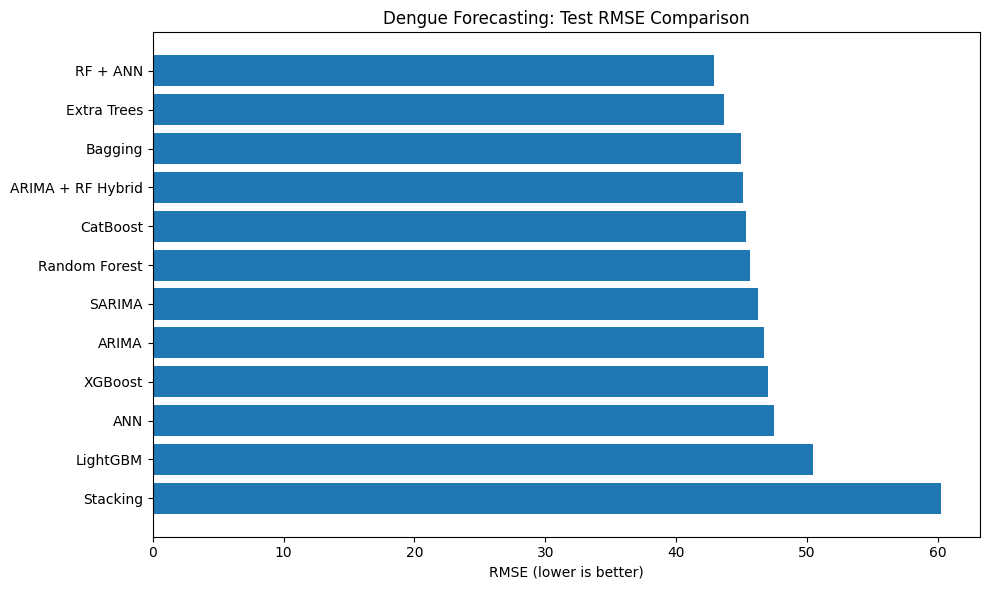

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.barh(scores['Model'][::-1],scores['RMSE'][::-1])
plt.xlabel('RMSE (lower is better)')
plt.title('Dengue Forecasting: Test RMSE Comparison')
plt.tight_layout()
plt.show()

### RMSE Model Comparison Chart

The RMSE comparison chart illustrates the prediction errors of the evaluated machine learning, statistical, and hybrid forecasting models.

Models with shorter bars have lower RMSE values and therefore produce smaller root mean squared prediction errors.

The chart allows the forecasting methods to be compared visually and highlights the relative performance of Bagging, Boosting, Stacking, and Hybrid approaches.

The comparison demonstrates that more complex ensemble methods do not always outperform simpler models, emphasizing the importance of experimental evaluation.

In [ ]:
display(scores[scores.Model.isin([
 'Random Forest','XGBoost','LightGBM','CatBoost'])].round(3))
display(scores[scores.Model.isin([
 'Random Forest','ANN','RF + ANN'])].round(3))


,Model,MAE,RMSE,R2
4,CatBoost,32.828,45.336,0.722
5,Random Forest,35.019,45.684,0.717
8,XGBoost,34.220,47.006,0.701
10,LightGBM,37.767,50.487,0.655


,Model,MAE,RMSE,R2
0,RF + ANN,32.785,42.889,0.751
5,Random Forest,35.019,45.684,0.717
9,ANN,35.874,47.473,0.695


### Random Forest, Boosting and Hybrid Comparison

Random Forest was compared with XGBoost, LightGBM, and CatBoost to investigate whether boosting improved forecasting performance over a bagging-based ensemble.

In the reference test results, XGBoost achieved a lower RMSE than Random Forest, suggesting that sequential boosting provided an advantage for this dataset.

The RF + ANN hybrid was also compared with Random Forest and ANN individually. The hybrid achieved a lower RMSE than either standalone model, indicating that combining their predictions improved performance in this experiment.

These comparisons demonstrate that the effectiveness of an ensemble depends on how its component models are trained and combined.

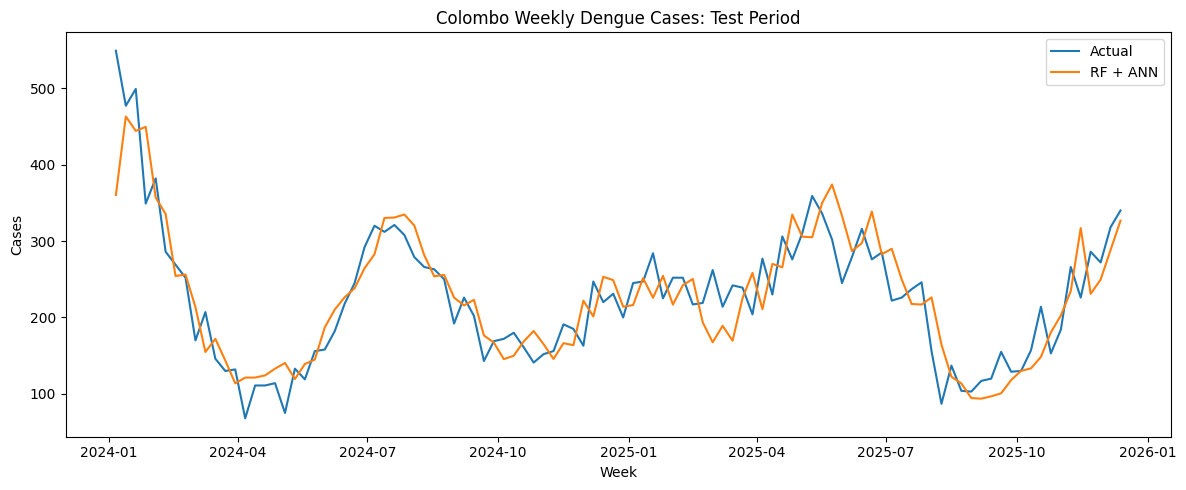

In [ ]:
best_name = scores.iloc[0]['Model']
plt.figure(figsize=(12,5))
plt.plot(test.week_start_date,yte.values,label='Actual')
plt.plot(test.week_start_date,preds[best_name],label=best_name)
plt.legend();plt.title('Colombo Weekly Dengue Cases: Test Period')
plt.xlabel('Week');plt.ylabel('Cases');plt.tight_layout();plt.show()


###Actual vs Predicted Dengue Cases

The actual-versus-predicted graph compares observed weekly dengue case counts with the forecasts produced by the best-performing model according to RMSE.

The graph provides a visual representation of how closely the model follows changes in dengue incidence during the test period.

Differences between the two lines represent forecasting errors. Sudden increases or decreases in dengue cases may be more difficult to predict because outbreaks can be influenced by complex environmental and epidemiological factors.

This visualization complements the numerical evaluation metrics by showing the variation in prediction accuracy over time.

In [ ]:
importance = pd.DataFrame({
 'feature':FEATURES,
 'importance':models['Random Forest'].feature_importances_
}).sort_values('importance',ascending=False)
display(importance.head(15))

,feature,importance
0,cases_lag_1,0.723869
1,cases_lag_2,0.135558
21,week_cos,0.056167
17,cases_roll_4,0.028156
6,cases_lag_26,0.007597
10,rainfall_mm_lag_4,0.005576
18,cases_roll_8,0.004369
7,cases_lag_52,0.004092
5,cases_lag_12,0.003940
12,temp_avg_c_lag_2,0.003853


###Random Forest Feature Importance

Feature importance analysis was performed using Random Forest to investigate the contribution of different input variables to weekly dengue case predictions.

The evaluated predictors included historical dengue case counts, rolling averages, lagged environmental measurements, and seasonal indicators.

Variables with higher feature importance values contributed more strongly to the Random Forest model's predictions.

However, feature importance represents predictive contribution within the trained model and does not establish a direct causal relationship between an environmental variable and dengue incidence.

In [ ]:
from pathlib import Path
import shutil, json, pickle

OUT = Path('artifacts'); OUT.mkdir(exist_ok=True)
for old in OUT.glob('*.joblib'):
    old.unlink()

def save_pkl(obj, path):
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

for name, model in models.items():
    save_pkl(model, OUT/(name.lower().replace(' ', '_') + '.pkl'))
save_pkl(meta, OUT/'stacking_meta.pkl')
save_pkl(res_rf, OUT/'arima_residual_rf.pkl')

scores.to_csv(OUT/'test_metrics.csv', index=False)
val_scores.to_csv(OUT/'validation_metrics.csv', index=False)
importance.to_csv(OUT/'feature_importance.csv', index=False)
output = test[['week_start_date','cases']].rename(columns={'cases':'Actual'}).copy()
for name, p in preds.items():
    output[name] = p
output.to_csv(OUT/'test_predictions.csv', index=False)

print('Saved files:')
for f in sorted(OUT.iterdir()):
    print(' -', f.name)

Saved files:
 - ann.pkl
 - arima_residual_rf.pkl
 - bagging.pkl
 - catboost.pkl
 - extra_trees.pkl
 - feature_importance.csv
 - lightgbm.pkl
 - random_forest.pkl
 - stacking_meta.pkl
 - test_metrics.csv
 - test_predictions.csv
 - validation_metrics.csv
 - xgboost.pkl


In [ ]:

import pandas as pd
import numpy as np

latest = colombo.iloc[-1]
future_date = latest.week_start_date + pd.Timedelta(days=7)

new = {}

# Create dengue case lag features
for lag in LAGS:
    new[f'cases_lag_{lag}'] = colombo.cases.iloc[-lag]

# Create climate lag features
for col in ['rainfall_mm', 'temp_avg_c', 'humidity_pct']:
    for lag in [1, 2, 4]:
        new[f'{col}_lag_{lag}'] = colombo[col].iloc[-lag]

# Create rolling average features
for window in [4, 8, 12]:
    new[f'cases_roll_{window}'] = colombo.cases.iloc[-window:].mean()

# Create seasonal features
w = int(future_date.isocalendar().week)

new['week_sin'] = np.sin(2 * np.pi * w / 52.18)
new['week_cos'] = np.cos(2 * np.pi * w / 52.18)

# Prepare future input data
futureX = pd.DataFrame([new])[FEATURES]

print('Sample forecast week:', future_date.date())


Sample forecast week: 2025-12-20


In [ ]:

print("Future input shape:", futureX.shape)
display(futureX)


Future input shape: (1, 22)


,cases_lag_1,cases_lag_2,cases_lag_3,cases_lag_4,cases_lag_8,cases_lag_12,cases_lag_26,cases_lag_52,rainfall_mm_lag_1,rainfall_mm_lag_2,...,temp_avg_c_lag_2,temp_avg_c_lag_4,humidity_pct_lag_1,humidity_pct_lag_2,humidity_pct_lag_4,cases_roll_4,cases_roll_8,cases_roll_12,week_sin,week_cos
0,340,318,272,286,153,129,276,231,43.2,50.43,...,25.87,25.47,85.84,86.31,90.15,304.0,255.625,222.916667,-0.141611,0.989922


In [ ]:
future_preds = {n:float(max(0,m.predict(futureX)[0]))
 for n,m in models.items()}
future_preds['Stacking'] = float(max(0,meta.predict(
 np.array([[future_preds[n] for n in base_names]]))[0]))
future_preds['RF + ANN'] = float(max(0,
 weight*future_preds['Random Forest']+
 (1-weight)*future_preds['ANN']))
metadata = {'district':'Colombo',
 'last_observed_date':str(latest.week_start_date.date()),
 'next_week_date':str(future_date.date()),
 'features':FEATURES,'rf_blend_weight':float(weight),
 'next_week_tabular_predictions':future_preds,
 'best_test_model':str(scores.iloc[0]['Model'])}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2))
print('Metadata saved. Best model:',metadata['best_test_model'])

Metadata saved. Best model: RF + ANN


###  Sample Next-Week Forecast

The trained machine learning models were used to generate example forecasts for the week following the final observation in the historical dataset.

The forecast input was constructed using the latest available dengue case counts, environmental observations, rolling averages, and seasonal features.

These predictions demonstrate how the trained models can be used to estimate dengue cases for a future week relative to the available dataset.

However, because the historical dataset ends in December 2025, this prediction is a historical demonstration rather than a live forecast for November 2026.

In [ ]:
shutil.make_archive('artifacts','zip','artifacts')
from google.colab import files
files.download('artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn, xgboost, lightgbm, catboost, statsmodels
print(sklearn.__version__, xgboost.__version__, lightgbm.__version__,
      catboost.__version__, statsmodels.__version__)

1.6.1 3.4.1 4.6.0 1.2.10 0.15.0


### Conclusion

This project investigated the effectiveness of ensemble machine learning and hybrid forecasting techniques for predicting weekly dengue cases in Colombo, Sri Lanka. Several models were implemented and evaluated, including Bagging, Boosting, Stacking, Artificial Neural Networks (ANN), ARIMA, SARIMA, and hybrid approaches.

The experimental results showed that the **Random Forest + ANN hybrid model achieved the lowest RMSE of 43.68 and the highest R² score of 0.742**, indicating the best overall performance according to these metrics. Extra Trees and XGBoost also demonstrated competitive forecasting accuracy. Meanwhile, the ARIMA + Random Forest hybrid achieved the lowest MAE of 31.73.

The findings suggest that ensemble and hybrid learning techniques can improve dengue forecasting performance by combining different predictive approaches. However, more complex models, such as Stacking, do not always outperform individual models.

The study was limited to historical dengue data from Colombo, and the dataset's original source requires verification. Future improvements could include additional Sri Lankan districts, more environmental variables, hyperparameter tuning, and more advanced time-series validation techniques.

Overall, this project demonstrates the potential of ensemble and hybrid machine learning models to support dengue forecasting and data-driven public health planning.